## Packages

In [3]:
from datetime import datetime, timedelta
import pandas as pd
import os
from sunpy.net import Fido, attrs as a
from sunpy.timeseries import TimeSeries
from sunpy.timeseries.sources.goes import XRSTimeSeries
import astropy.units as u
from sunkit_instruments.goes_xrs import calculate_temperature_em
import matplotlib.pyplot as plt
import numpy as np
from sunpy.data import manager
import netCDF4 as nc
import os
import pandas as pd
from datetime import datetime, timedelta
import copy
from matplotlib import colormaps
list(colormaps)
#from colorspacious import cspace_converter
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import cm
from matplotlib.colors import ListedColormap
import matplotlib.dates as mdates
from matplotlib.ticker import LogFormatter
from matplotlib.ticker import LogFormatterMathtext
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import FuncFormatter
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import seaborn as sns
import re
import glob

/Users/nohoraprieto/miniforge3/envs/sunpy/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters

In [4]:
# ============================================================
# 1. PARÁMETROS DEL ANÁLISIS
# ============================================================
n=16752
new_n = 8164 # nuevo número de días
fecha_actual = "2025-12-01"
# Parámetros de FAI
window_minutes=30
fai_temp_range = (8, 35)
fai_em_jump = 0.07
fai_em_threshold_d=fai_em_jump
date_column = "date"
duration = True
FAI_duration = 4
exclude_last_minutes = 20 # minutos al final del día para excluir FAIs
filter_flare_coincidence = True
method = "filteredend_nooverlap" # "all", "true", "filtered", "filteredend" o "filteredend_nooverlap"
flares="ABCMX" # "valid", "no_A", "no_A_B", 
                                  # "no_A_B_nonoverlap" o "no_A_B_nonoverlap_wstart"
                                  # "M_X_nonoverlap_wstart"
nooverlap = True
min_gap_minutes_overlap = 20 #FILTRO EXTRA: remover FAI que ocurren tras un flare en [end, end + min_gap_minutes_overlap] 

# Formato de threshold para nombres de carpetas
threshold_str = f"{fai_em_jump}"   # "0.005" # convertir a string sin notación científica
fai_em_threshold_d = threshold_str.replace(".", "d") # reemplazar el punto por 'd'

## Carpeta para gráficas

In [5]:
analysis_dir = os.path.join(f"Data_for_{n}_days/Analysis_FAI")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_dir ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_dir }")
else:
    os.makedirs(analysis_dir , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_dir}")

# Crear subcarpeta para guardar resultados de análisis
analysis_esp = os.path.join(analysis_dir, f"Analysis_FAI_{flares}_T{fai_temp_range[0]}-{fai_temp_range[1]}_dEM{fai_em_threshold_d}_dur{FAI_duration}min")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_esp ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_esp }")
else:
    os.makedirs(analysis_esp , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_esp}")

folder = f"Graphics_{method}_W{window_minutes}min"

# Crear subcarpeta para guardar resultados de análisis
graphics_dir = os.path.join(analysis_esp, folder)
# Crear subcarpeta para guardar resultados de análisis (si no existe) y mostrar mensaje
if os.path.exists(graphics_dir):
    print(f"⚠️ La carpeta de análisis ya existía: {graphics_dir}")
else:
    os.makedirs(graphics_dir , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {graphics_dir}") 



⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI
⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min
⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min


## Valid Data 

In [6]:
output_dir = f"Data_for_{n}_days"

# Path of cleaned data in csv
csv_path_full_valid = f"{output_dir}/df_full_{new_n}_valid.csv"
# Path of valid flares: 
csv_path_flares = f"{output_dir}/df_flares_{new_n}_{flares}.csv"
# Path of df_full
csv_path_full = f"{output_dir}/all_df_full_{n}.csv"

# Verificar existencia de archivos y avisar
if not os.path.exists(csv_path_full_valid):
    print(f"⚠️ No se encontró el archivo GOES: {csv_path_full_valid}")
else:
    print(f"✅ Archivo GOES encontrado: {csv_path_full_valid}")

if not os.path.exists(csv_path_flares):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_flares}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_flares}")

if not os.path.exists(csv_path_full):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_full}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_full}")

df_full_valid = pd.read_csv(csv_path_full_valid)
df_flares_valid = pd.read_csv(csv_path_flares)
df_full = pd.read_csv(csv_path_full)

✅ Archivo GOES encontrado: Data_for_16752_days/df_full_8164_valid.csv
✅ Archivo de flares encontrado: Data_for_16752_days/df_flares_8164_ABCMX.csv
✅ Archivo de flares encontrado: Data_for_16752_days/all_df_full_16752.csv


## Data_method

In [7]:
# Path of anticipation_time
csv_path_anticipation_time = f"{analysis_esp}/df_anticipation_time_{method}_(W_{window_minutes})_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of fai_all
csv_path_fai_all = f"{analysis_esp}/df_fai_all_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of fai_selected
csv_path_fai_selected = f"{analysis_esp}/df_fai_{method}_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of df_fai_assoc
csv_path_fai_assoc = f"{analysis_esp}/df_fai_assoc_{method}_(W_{window_minutes})_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"

if not os.path.exists(csv_path_anticipation_time):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_anticipation_time}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_anticipation_time}")
if not os.path.exists(csv_path_fai_all):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_all}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_all}")
if not os.path.exists(csv_path_fai_selected):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_selected}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_selected}")
if not os.path.exists(csv_path_fai_assoc):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_assoc}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_assoc}")


df_anticipation_time = pd.read_csv(csv_path_anticipation_time)
df_fai_all = pd.read_csv(csv_path_fai_all)
df_fai_selected = pd.read_csv(csv_path_fai_selected)
df_fai_assoc = pd.read_csv(csv_path_fai_assoc)



✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/df_anticipation_time_filteredend_nooverlap_(W_30)_T8-35_EM0d07_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/df_fai_all_T8-35_EM0d07_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/df_fai_filteredend_nooverlap_T8-35_EM0d07_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/df_fai_assoc_filteredend_nooverlap_(W_30)_T8-35_EM0d07_dur4min.csv


In [8]:

# Filtramos solo FAIs asociados a flares (opcional si se quiere eliminar falsos positivos)
df_associated = df_fai_assoc[df_fai_assoc["Associated_Flare"] == True].copy()


## dfs columns to datatime

In [9]:
df_full_valid["date"] = pd.to_datetime(df_full_valid["date"])
df_flares_valid["StartTime"] = pd.to_datetime(df_flares_valid["StartTime"])
df_flares_valid["PeakTime"]  = pd.to_datetime(df_flares_valid["PeakTime"])
df_flares_valid["EndTime"]   = pd.to_datetime(df_flares_valid["EndTime"])
df_anticipation_time["StartTime"] = pd.to_datetime(df_anticipation_time["StartTime"])
df_anticipation_time["PeakTime"]  = pd.to_datetime(df_anticipation_time["PeakTime"])
df_anticipation_time["EndTime"]   = pd.to_datetime(df_anticipation_time["EndTime"])
df_fai_selected["date"] = pd.to_datetime(df_fai_selected["date"])

## Funciones gráficas

In [10]:
# Plot with ticks every minute
def plot_fai_and_flare_lines(df_combined, df_fai_selected, df_fai_all, df_flare_data, 
                              flare_start_time, flare_end_time, graphics_dir,
                              ymin=1e-9, ymax=1e-4):
    """
    Plots XRS A and B on a logarithmic scale with vertical lines for FAI events and flare times.
    df_fai_all: all candidate FAI events
    df_fai_selected: FAI events selected by a method
    """
    import matplotlib.dates as mdates
    import os
    
    # Ensure time types
    flare_start_time = pd.to_datetime(flare_start_time)
    flare_end_time = pd.to_datetime(flare_end_time)
    
    print(f"Buscando datos entre: {flare_start_time} y {flare_end_time}")

    # Convert date columns to datetime if they aren't already
    df_combined['date'] = pd.to_datetime(df_combined['date'])
    df_fai_selected['date'] = pd.to_datetime(df_fai_selected['date'])
    df_fai_all['date'] = pd.to_datetime(df_fai_all['date'])
    df_flare_data['StartTime'] = pd.to_datetime(df_flare_data['StartTime'])
    df_flare_data['PeakTime'] = pd.to_datetime(df_flare_data['PeakTime'])
    df_flare_data['EndTime'] = pd.to_datetime(df_flare_data['EndTime'])

    # DEBUG: Verificar rangos de fechas en los dataframes
    print(f"Rango df_combined: {df_combined['date'].min()} a {df_combined['date'].max()}")
    print(f"Rango df_fai_selected: {df_fai_selected['date'].min()} a {df_fai_selected['date'].max()}")
    print(f"Rango df_flare_data PeakTime: {df_flare_data['PeakTime'].min()} a {df_flare_data['PeakTime'].max()}")

    # Filter data based on date column - método más robusto
    mask_combined = (df_combined['date'] >= flare_start_time) & (df_combined['date'] <= flare_end_time)
    df_plot = df_combined.loc[mask_combined].copy()
    
    mask_fai = (df_fai_selected['date'] >= flare_start_time) & (df_fai_selected['date'] <= flare_end_time)
    df_fai_interval = df_fai_selected.loc[mask_fai].copy()

    mask_fai_all = (df_fai_all['date'] >= flare_start_time) & (df_fai_all['date'] <= flare_end_time)
    df_fai_all_interval = df_fai_all.loc[mask_fai_all].copy()


    # DEBUG: Verificar cuántos datos encontramos
    print(f"Datos en df_plot: {len(df_plot)}")
    print(f"Datos en df_fai_interval: {len(df_fai_interval)}")

    # Si no hay datos en el rango, mostrar advertencia
    if len(df_plot) == 0:
        print(f"¡ADVERTENCIA! No hay datos en df_combined para el rango {flare_start_time} a {flare_end_time}")
        return

    plt.rcParams.update({
        "axes.titlesize": 16, "axes.labelsize": 16, 
        "xtick.labelsize": 15, "ytick.labelsize": 15, 
        "legend.fontsize": 13
    })

    # Create figure
    fig, ax = plt.subplots(figsize=(13, 5))

    # Plot XRS A and B usando el índice numérico para evitar problemas con fechas
    x_vals = range(len(df_plot))  # Usar índice numérico para el plotting
    ax.plot(x_vals, df_plot['xrsa'], label='XRS A', color='blue', linewidth=1)
    ax.plot(x_vals, df_plot['xrsb'], label='XRS B', color='red', linewidth=1)

    # Log scale and Y-axis limits
    ax.set_yscale('log')
    ax.set_ylim(ymin, ymax)
    ax.set_ylabel('X-ray Flux [W/m²]')
    ax.set_xlabel(f"Time [UTC] – {flare_start_time:%d %b %Y}")
    ax.set_title(f'XRS A and B with FAI and Flare Times\n{flare_start_time:%Y-%m-%d %H:%M} to {flare_end_time:%H:%M}')
    ax.grid(True, alpha=0.3)
    
    # -----------------------
    # Configure X axis ticks
    # -----------------------
    # Crear un array de minutos dentro del intervalo de flare
    start_time = flare_start_time
    end_time = flare_end_time

    # Generar ticks mayores cada 10 minutos
    major_times = pd.date_range(start=start_time.ceil('10min'), end=end_time, freq='10min')
    major_indices = [(np.abs(df_plot['date'] - t)).argmin() for t in major_times]
    major_labels = [t.strftime('%H:%M') for t in major_times]

    # Generar ticks menores cada 1 minuto
    minor_times = pd.date_range(start=start_time.ceil('1min'), end=end_time, freq='1min')
    minor_indices = [(np.abs(df_plot['date'] - t)).argmin() for t in minor_times]

    # Asignar ticks al eje X
    ax.set_xticks(major_indices)
    ax.set_xticklabels(major_labels)
    ax.set_xticks(minor_indices, minor=True)  # minor ticks sin etiquetas
    

    # -----------------------
    # Plot all FAI candidates (background)
    # -----------------------
    for i, fai_time in enumerate(df_fai_all_interval['date']):
        idx = (np.abs(df_plot['date'] - fai_time)).argmin()
        ax.axvline(x=idx, color='#FF69B4', linestyle='-', linewidth=1.5, alpha=0.7,
                   label='FAI Candidate' if i == 0 else "")


    # Red vertical lines: FAI events
    for fai_time in df_fai_interval['date']:
        # Encontrar la posición en el plot para este tiempo FAI
        time_diff = np.abs(df_plot['date'] - fai_time)
        if len(time_diff) > 0:
            idx = time_diff.argmin()
            ax.axvline(x=idx, color='red', linestyle='-', linewidth=1.5, alpha=0.7,
                      label='FAI Alert' if fai_time == df_fai_interval['date'].iloc[0] else "")

    # Encontrar fulguraciones en el intervalo de tiempo
    flares_in_interval = df_flare_data[
        (df_flare_data['PeakTime'] >= flare_start_time) & 
        (df_flare_data['PeakTime'] <= flare_end_time)
    ]
    
    print(f"Fulguraciones encontradas en el intervalo: {len(flares_in_interval)}")

    # Colores y estilos para los diferentes tiempos de las fulguraciones
    for idx, (_, row) in enumerate(flares_in_interval.iterrows()):
        start_time = row['StartTime']
        peak_time = row['PeakTime']
        end_time = row['EndTime']
        flare_class = row.get('Class', '')
        
        # Función para encontrar la posición en el plot
        def find_time_position(time_val):
            time_diff = np.abs(df_plot['date'] - time_val)
            if len(time_diff) > 0:
                return time_diff.argmin()
            return None
        
        # Línea verde punteada para StartTime
        if flare_start_time <= start_time <= flare_end_time:
            start_pos = find_time_position(start_time)
            if start_pos is not None:
                ax.axvline(x=start_pos, color='green', linestyle=(0, (5, 3)), linewidth=2, alpha=0.8,
                          label='Flare Start' if idx == 0 else "")
        
        # Línea azul discontinua para PeakTime
        if flare_start_time <= peak_time <= flare_end_time:
            peak_pos = find_time_position(peak_time)
            if peak_pos is not None:
                #ax.axvline(x=peak_pos, color='blue', linestyle='--', linewidth=2, alpha=0.8,
                ax.axvline(x=peak_pos, color='blue', linestyle=(0, (5, 3)), linewidth=2, alpha=0.8,
                          label='Flare Peak' if idx == 0 else "")
                
                # AÑADIR FLECHA QUE SEÑALA EL PEAK
                # Encontrar el valor de flujo en el peak time
                peak_flux = None
                peak_time_diff = np.abs(df_plot['date'] - peak_time)
                if len(peak_time_diff) > 0:
                    peak_idx = peak_time_diff.argmin()
                    # Usar el mayor flujo entre XRS A y XRS B
                    peak_flux = max(df_plot['xrsa'].iloc[peak_idx], df_plot['xrsb'].iloc[peak_idx])
                

        
        # Línea amarilla punteada para EndTime
        if flare_start_time <= end_time <= flare_end_time:
            end_pos = find_time_position(end_time)
            if end_pos is not None:
                ax.axvline(x=end_pos, color='orange', linestyle='--', linewidth=3, alpha=0.8,
                          label='Flare End' if idx == 0 else "")
        
        # Anotación con la clase de la fulguración Y FLECHA
        if flare_class and (flare_start_time <= peak_time <= flare_end_time):
            peak_pos = find_time_position(peak_time)
            if peak_pos is not None:
                ax.annotate(flare_class,
                            xy=(peak_pos, ymin * 5),  # Punto destino
                            xytext=(peak_pos + 1, ymin * 15),  # Punto origen (más a la derecha y arriba)
                            fontsize=9,
                            color='darkblue',
                            rotation=0,
                            ha='left',
                            va='center',
                            bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="darkblue", lw=1, alpha=0.8),
                            arrowprops=dict(arrowstyle='->',  # Flecha
                                          color='darkblue',
                                          lw=1,
                                          alpha=0.7,
                                          shrinkA=5,  # Espacio en el origen
                                          shrinkB=0))  # Sin espacio en el destino

    # Final layout with proper legend handling
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))  # Remove duplicates
    ax.legend(by_label.values(), by_label.keys(), loc="upper right")
    

    fig.tight_layout()

    # Create graphics directory if it doesn't exist
    #graphics_dir = "graphics"
    #os.makedirs(graphics_dir, exist_ok=True)

    #en esta función se recibe el directorio como parámetro
    
    output_name = f"FAI_{flare_start_time:%Y%m%d_%H%M}_{flare_end_time:%H%M}.png"
    output_path = os.path.join(graphics_dir, output_name)
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


#gráfica ce flux vs EM y T
def plot_xrs_vs_te_simple(days, 
                         df_full_valid, 
                         df_flares_valid, 
                         time_column="PeakTime",
                         XRS="xrsb_corr", T="T_cor", EM="EM_cor_norm",
                         color_by=None,
                         palette="viridis",  
                         class_to_color=None):
    """
    Versión simplificada que asume que podemos hacer merge por tiempo
    """
    
    # Convertir a datetime
    df_full_valid['date'] = pd.to_datetime(df_full_valid['date'])
    df_flares_valid[time_column] = pd.to_datetime(df_flares_valid[time_column])
    
    # Hacer merge de los dataframes
    df_merged = pd.merge(df_flares_valid, df_full_valid, 
                        left_on=time_column, 
                        right_on='date', 
                        how='inner')
    
    if len(df_merged) == 0:
        print("No hay coincidencias entre los dataframes.")
        return
    
    # Filtrar datos válidos
    valid_data = df_merged.dropna(subset=[XRS, T, EM])
    
    if len(valid_data) == 0:
        print("No hay datos válidos después de filtrar NaNs.")
        return
    
    print(f"Datos válidos para graficar: {len(valid_data)}")
    
    # Preparar datos
    xrs_vals = valid_data[XRS].values
    em_vals = valid_data[EM].values
    t_vals = valid_data[T].values
    
    # Preparar labels para colores
    if color_by == "Class":
        flare_labels = valid_data["Class"].astype(str).str[0].tolist()  # solo letra B,C,M,X
    elif color_by == "Date":
        flare_labels = valid_data[time_column].dt.date.astype(str).tolist()
    elif color_by == "observatory":
        flare_labels = valid_data["observatory"].fillna("Unknown").tolist()
    else:
        flare_labels = [""] * len(valid_data)

    # --- Colores según selección ---
    if color_by:
        labels = sorted(set(flare_labels))
        if class_to_color is None:
            cmap = plt.get_cmap(palette, len(labels))
            class_to_color = {lab: cmap(i) for i, lab in enumerate(labels)}
        colors = [class_to_color[lab] for lab in flare_labels]
    else:
        labels = []
        colors = "blue"

    # Configuración de plot
    plt.rcParams.update({
        "axes.titlesize": 17, "axes.labelsize": 15,
        "xtick.labelsize": 16, "ytick.labelsize": 16,
        "legend.fontsize": 16
    })

    fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

    # XRS vs EM
    axes[0].scatter(em_vals, xrs_vals, c=colors, alpha=0.7, s=50)
    axes[0].set_xlabel(rf"EM$_{{49}}$ [cm$^{{-3}}$]")
    axes[0].set_ylabel(rf"{XRS} [W/m$^2$]")
    axes[0].set_title(f"X-ray flux vs Emission Measure\n{days} days ({time_column})", pad=20)
    axes[0].set_xscale("log")
    axes[0].set_yscale("log")
    axes[0].set_xlim(0.001, None)
    
    # XRS vs T
    axes[1].scatter(t_vals, xrs_vals, c=colors, alpha=0.7, s=50)
    axes[1].set_xlabel(f"T [MK]")
    axes[1].set_ylabel(rf"{XRS} [W/m$^2$]")
    axes[1].set_title(f"X-ray flux vs Temperature\n{days} days ({time_column})", pad=20)
    axes[1].set_xscale("linear")
    axes[1].set_yscale("log")
    axes[1].set_xlim(0, 30)

    # Leyenda
    if color_by and labels:
        handles = [plt.Line2D([], [], marker="o", color=class_to_color[lab], linestyle="", 
                             label=str(lab), markersize=12) for lab in labels]
        
        n_labels = len(labels)

        # Obtener posición de los subplots combinados (en coordenadas de la figura)
        pos0 = axes[0].get_position()
        pos1 = axes[1].get_position()
        subplot_left = pos0.x0
        subplot_right = pos1.x1
        subplot_width = subplot_right - subplot_left
        
        # Número de columnas dinámico según ancho de subplots
        items_per_row = max(1, int(subplot_width * 12))  # escala arbitraria, ajustar si se quiere
        ncol = min(n_labels, items_per_row)
        n_rows = int(np.ceil(n_labels / ncol))

        fig.legend(handles=handles, title=color_by,
                  loc="upper center", bbox_to_anchor=(0.5, -0.05),
                  ncol=min(4, len(labels)), frameon=False,
                  title_fontsize=17) #tamaño de título

    # Guardar
    output_name = f"{days}d_{XRS}_vs_{T}_{EM}_{time_column}_{color_by}.png"
    output_path = os.path.join(graphics_dir, output_name)
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


##

# Gráficas

## Histograma de tiempos de anticipación

In [11]:
def plot_histogram_with_reference(
    df, column, delta_x=5, figsize=(10,5), 
    save_plot=False, graphics_dir=None, 
    plot_name=None, dpi=300,
    text_x=0.03, text_y=0.85,
    x_min=None, x_max=None
):
    """  
    Crea un histograma con línea de referencia en 0 y estadísticas.
    Permite límites opcionales del eje X.
    """
    
    import numpy as np
    import matplotlib.pyplot as plt
    import os
    from datetime import datetime
    
    # --------------------------------------------------
    # DATOS
    # --------------------------------------------------
    x = df[column].dropna()
    
    # --------------------------------------------------
    # DEFINICIÓN DE BINS (centrados en múltiplos de delta_x)
    # --------------------------------------------------
    min_val = x.min()
    max_val = x.max()
    
    min_val_ajustado = delta_x * np.floor(min_val / delta_x)
    max_val_ajustado = delta_x * np.ceil(max_val / delta_x)
    
    bin_edges = np.arange(min_val_ajustado, max_val_ajustado + delta_x, delta_x)
    
    # Histograma (para usar counts después)
    counts, edges = np.histogram(x, bins=bin_edges)
    bin_width = edges[1] - edges[0]
    
    # --------------------------------------------------
    # TIPO DE REFERENCIA SEGÚN COLUMNA
    # --------------------------------------------------
    column_lower = column.lower()
    if 'peak' in column_lower:
        reference_type = 'peak'
        reference_label = 'Flare peak'
    elif 'end' in column_lower:
        reference_type = 'end'
        reference_label = 'Flare end'
    else:
        reference_type = 'start'
        reference_label = 'Flare start'
    
    plot_title = f'Histogram of anticipation time relative to flare {reference_type}'
    
    # --------------------------------------------------
    # FIGURA
    # --------------------------------------------------
    plt.figure(figsize=figsize)
    plt.hist(x, bins=bin_edges, color='orange', edgecolor='black', alpha=0.6)
    
    # --------------------------------------------------
    # LÍMITES DEL EJE X (OPCIONALES)
    # --------------------------------------------------
    if x_min is not None and x_max is not None:
        x_left, x_right = x_min, x_max
    elif x_min is not None:
        x_left, x_right = x_min, max_val_ajustado
    elif x_max is not None:
        x_left, x_right = min_val_ajustado, x_max
    else:
        x_left, x_right = min_val_ajustado, max_val_ajustado
    
    plt.xlim(x_left, x_right)
    
    # --------------------------------------------------
    # LÍNEAS DE REFERENCIA
    # --------------------------------------------------
    plt.axvline(0, color='red', linestyle='--', linewidth=2, label=reference_label)
    plt.axvline(min_val, color='blue', linestyle=':', linewidth=2, label=f'Min = {min_val:.1f}')
    plt.axvline(max_val, color='green', linestyle=':', linewidth=2, label=f'Max = {max_val:.1f}')
    
    # --------------------------------------------------
    # ETIQUETAS Y ESTILO
    # --------------------------------------------------
    plt.xlabel(f'{column} (minutes relative to flare {reference_type})', fontsize=12)
    plt.ylabel('Number of FAIs', fontsize=12)
    plt.title(plot_title, fontsize=14)
    plt.legend(loc='upper right')
    
    # --------------------------------------------------
    # TICKS PRINCIPALES (cada 10 min)
    # --------------------------------------------------
    start_tick_major = 10 * np.floor(x_left / 10)
    end_tick_major   = 10 * np.ceil(x_right / 10)
    
    major_ticks = np.arange(start_tick_major, end_tick_major + 10, 10)
    major_ticks = major_ticks[(major_ticks >= x_left) & (major_ticks <= x_right)]
    plt.xticks(major_ticks)
    
    # --------------------------------------------------
    # TICKS MENORES (cada 5 min)
    # --------------------------------------------------
    start_tick_minor = 5 * np.floor(x_left / 5)
    end_tick_minor   = 5 * np.ceil(x_right / 5)
    
    minor_ticks = np.arange(start_tick_minor, end_tick_minor + 5, 5)
    minor_ticks = minor_ticks[(minor_ticks >= x_left) & (minor_ticks <= x_right)]
    
    plt.gca().set_xticks(minor_ticks, minor=True)
    
    plt.gca().tick_params(axis='x', which='major', length=6, color='black')
    plt.gca().tick_params(axis='x', which='minor', length=3, color='black', labelbottom=False)
    
    plt.grid(alpha=0.3, which='major')
    plt.grid(alpha=0.15, which='minor', linestyle='--')
    
    # --------------------------------------------------
    # TEXTO INFORMATIVO
    # --------------------------------------------------
    plt.text(
        0.02, 0.95, f'Δx = {bin_width:.0f} min',
        transform=plt.gca().transAxes,
        fontsize=10, va='top',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )
    
    # --------------------------------------------------
    # ESTADÍSTICAS
    # --------------------------------------------------
    n_before = (x > 0).sum()
    n_equal  = (x == 0).sum()
    n_after  = (x < 0).sum()
    
    plt.text(
        text_x, text_y,
        f'Before (>0): {n_before}\nEqual (=0): {n_equal}\nAfter (<0): {n_after}',
        transform=plt.gca().transAxes,
        ha='left', va='top',
        fontsize=10,
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
    )
    
    # --------------------------------------------------
    # GUARDAR FIGURA
    # --------------------------------------------------
    saved_path = None
    if save_plot:
        if plot_name is None:
            safe_column = column.replace(' ', '_').replace('/', '_')
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            plot_name = f"histogram_{safe_column}_dx{delta_x}_{timestamp}.png"
        elif not plot_name.lower().endswith(('.png', '.jpg', '.jpeg', '.pdf', '.svg')):
            plot_name += '.png'
        
        if graphics_dir is not None:
            saved_path = os.path.join(graphics_dir, plot_name)
        else:
            saved_path = plot_name
        
        os.makedirs(os.path.dirname(saved_path) if os.path.dirname(saved_path) else '.', exist_ok=True)
        plt.savefig(saved_path, dpi=dpi, bbox_inches='tight')
        print(f"✓ Gráfica guardada en: {saved_path}")
    
    plt.tight_layout()
    plt.show()
    
    # --------------------------------------------------
    # RETORNO
    # --------------------------------------------------
    return {
        'min': min_val,
        'max': max_val,
        'n_before': n_before,
        'n_equal': n_equal,
        'n_after': n_after,
        'total': len(x),
        'bin_width': bin_width,
        'x_limits': (x_left, x_right),
        'saved_path': saved_path
    }


✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/histogram_FAI_to_start_dx1_20260120_002424.png


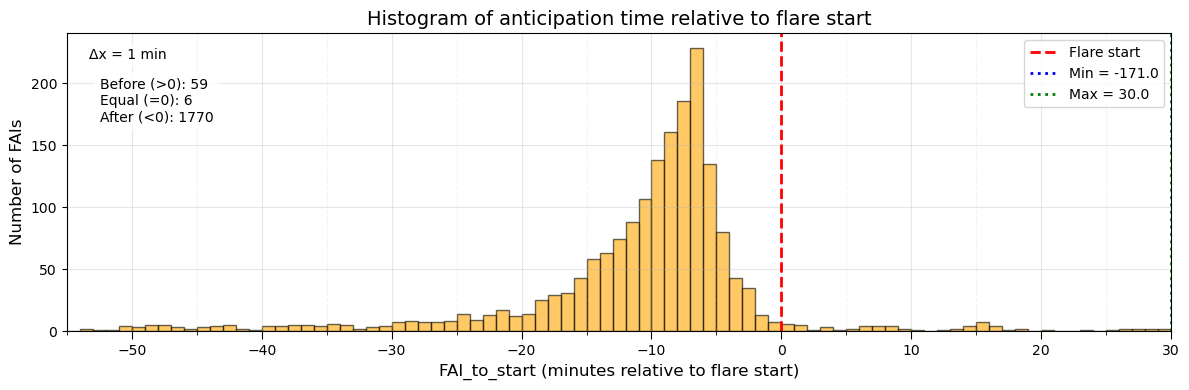

In [12]:
histogram1 = plot_histogram_with_reference(df_associated, 'FAI_to_start', 
                                             delta_x=1, figsize=(12,4), 
                                             save_plot=True, graphics_dir=graphics_dir, 
                                             plot_name=None, dpi=300,
                                             x_min=-55, x_max=None)

✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/histogram_FAI_to_peak_dx1_20260120_002425.png


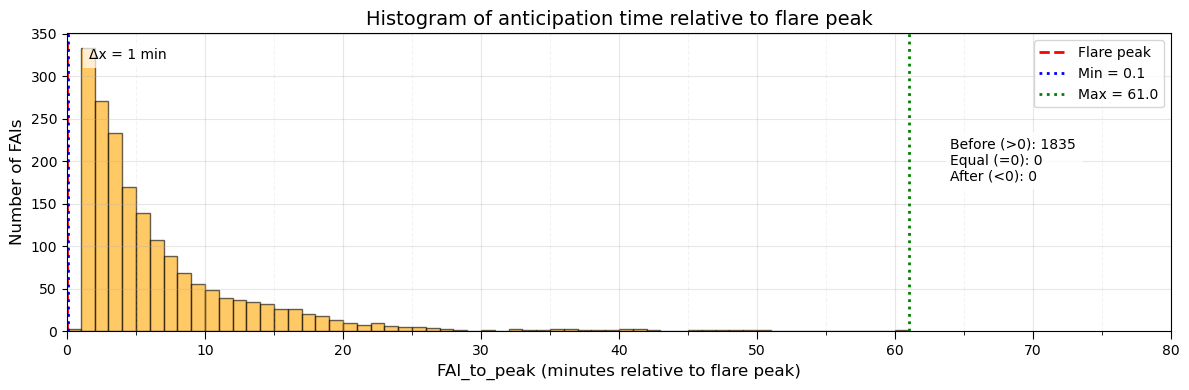

In [13]:
histogram2 = plot_histogram_with_reference(df_associated, 'FAI_to_peak', 
                                             delta_x=1, figsize=(12,4), 
                                             save_plot=True, graphics_dir=graphics_dir, 
                                             plot_name=None, dpi=300,
                                             text_x=0.8, text_y=0.65,
                                             x_min=None, x_max=80)

✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/histogram_FAI_to_end_dx1_20260120_002429.png


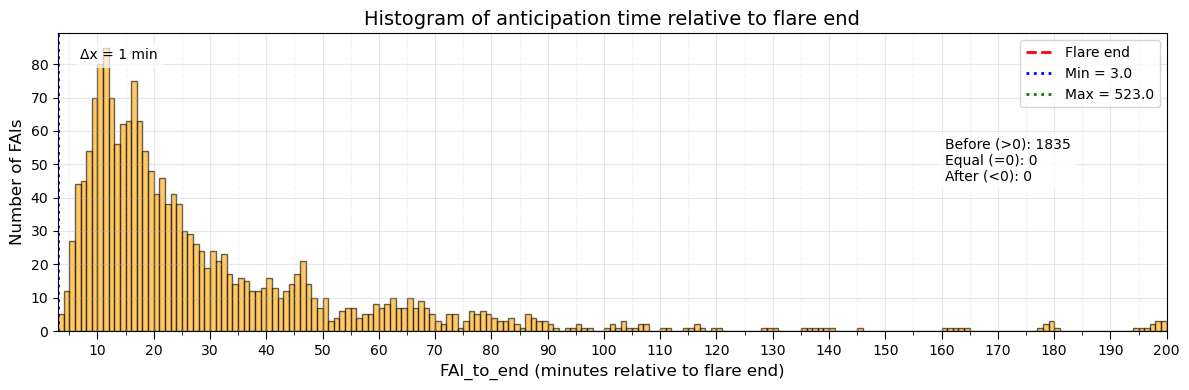

In [14]:
histogram1 = plot_histogram_with_reference(df_associated, 'FAI_to_end', 
                                             delta_x=1, figsize=(12,4), 
                                             save_plot=True, graphics_dir=graphics_dir, 
                                             plot_name=None, dpi=300,
                                             text_x=0.8, text_y=0.65,
                                             x_min=None, x_max=200)

## histogramas relativos al rise time

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import os
from datetime import datetime

def plot_relative_histogram(df, column_numerator, column_denominator='F_StartPeak', 
                           delta_x=0.1, figsize=(10,5), 
                           save_plot=False, graphics_dir=None, 
                           plot_name=None, dpi=300,
                           text_x=0.03, text_y=0.85,
                           xlim_min=None, xlim_max=None):
    """
    Crea un histograma relativo al tiempo de rise time del flare
    
    Parámetros adicionales:
    - xlim_min : float, opcional
        Límite mínimo del eje x
    - xlim_max : float, opcional
        Límite máximo del eje x
    """
    
    # Calcular la columna relativa
    df_temp = df.copy()
    df_temp['relative_column'] = df_temp[column_numerator] / df_temp[column_denominator]
    
    # Datos (eliminar NaN e infinitos)
    x = df_temp['relative_column'].replace([np.inf, -np.inf], np.nan).dropna()
    
    # Definir bins
    min_val = x.min()
    max_val = x.max()
    min_val_ajustado = delta_x * np.floor(min_val / delta_x)
    max_val_ajustado = delta_x * np.ceil(max_val / delta_x)
    bin_edges = np.arange(min_val_ajustado, max_val_ajustado + delta_x, delta_x)

    # Histograma
    counts, edges = np.histogram(x, bins=bin_edges)
    bin_width = edges[1] - edges[0]

    # Determinar tipo de referencia
    column_lower = column_numerator.lower()
    if 'peak' in column_lower:
        reference_type = 'peak'
        reference_label = 'Flare peak'
    elif 'end' in column_lower:
        reference_type = 'end'
        reference_label = 'Flare end'
    else:
        reference_type = 'start'
        reference_label = 'Flare start'

    # Título de la gráfica
    plot_title = f'Histogram of {reference_type} relative to flare rise time'

    # Gráfica
    plt.figure(figsize=figsize)
    plt.hist(x, bins=bin_edges, color='blue', edgecolor='black', alpha=0.7)

    # Líneas de referencia
    plt.axvline(0, color='red', linestyle='--', linewidth=2, label=reference_label)
    plt.axvline(min_val, color='blue', linestyle=':', linewidth=2, label=f'Min = {min_val:.2f}')
    plt.axvline(max_val, color='green', linestyle=':', linewidth=2, label=f'Max = {max_val:.2f}')

    # Etiquetas
    plt.xlabel(f'{column_numerator} / {column_denominator} (fraction of rise time)', fontsize=12)
    plt.ylabel('Number of FAIs', fontsize=12)
    plt.title(plot_title, fontsize=14)
    plt.legend(loc='upper right')
    plt.grid(alpha=0.3)

    # Ajustar límites del eje x si se pasan
    if xlim_min is not None or xlim_max is not None:
        plt.xlim(left=xlim_min, right=xlim_max)

    # Texto informativo
    plt.text(0.02, 0.95, 
             f'Δx = {bin_width:.2f}',
             transform=plt.gca().transAxes,
             fontsize=10, verticalalignment='top',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    # Estadísticas
    n_before = (x > 0).sum()   # FAI antes del start
    n_equal  = (x == 0).sum()  # FAI en el start
    n_after  = (x < 0).sum()   # FAI después del start

    plt.text(text_x, text_y,
             f'Before (>0): {n_before}\nEqual (=0): {n_equal}\nAfter (<0): {n_after}',
             transform=plt.gca().transAxes,
             ha='left', va='top',
             fontsize=10,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

    plt.tight_layout()
    
    # Guardar imagen
    if save_plot:
        if plot_name is None:
            safe_column_name = f"{column_numerator}_rel_{column_denominator}".replace(' ', '_').replace('/', '_')
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            plot_name = f"relative_histogram_{safe_column_name}_dx{delta_x}.png"
        elif not plot_name.lower().endswith(('.png', '.jpg', '.jpeg', '.pdf', '.svg')):
            plot_name += '.png'
        
        if graphics_dir is not None:
            save_path = os.path.join(graphics_dir, plot_name)
        else:
            save_path = plot_name
        
        os.makedirs(os.path.dirname(save_path) if os.path.dirname(save_path) else '.', exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight')
        print(f"✓ Gráfica guardada en: {save_path}")
    
    plt.show()
    
    return {
        'min': min_val,
        'max': max_val,
        'n_before': n_before,
        'n_equal': n_equal,
        'n_after': n_after,
        'total': len(x),
        'bin_width': bin_width,
        'saved_path': save_path if save_plot else None,
        'data_used': x
    }


✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/relative_histogram_FAI_to_start_rel_F_StartPeak_dx0.2.png


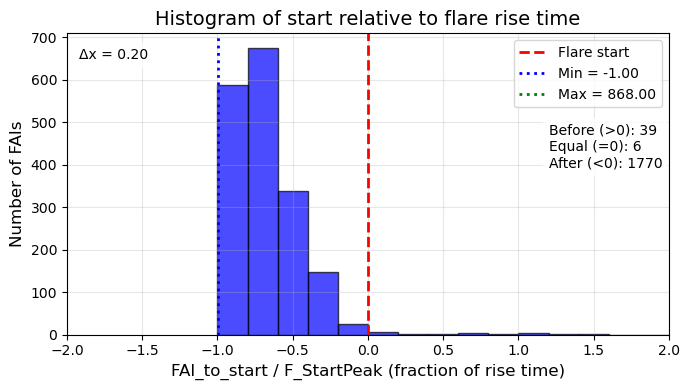

In [26]:
stats1 = plot_relative_histogram(df_associated, 'FAI_to_start', 
                           delta_x=0.2, figsize=(7,4), 
                           save_plot=True, graphics_dir=graphics_dir, 
                           plot_name=None, dpi=300,
                           text_x=0.8, text_y=0.7,
                           xlim_min=-2, xlim_max=2)

✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/relative_histogram_FAI_to_peak_rel_F_StartPeak_dx0.2.png


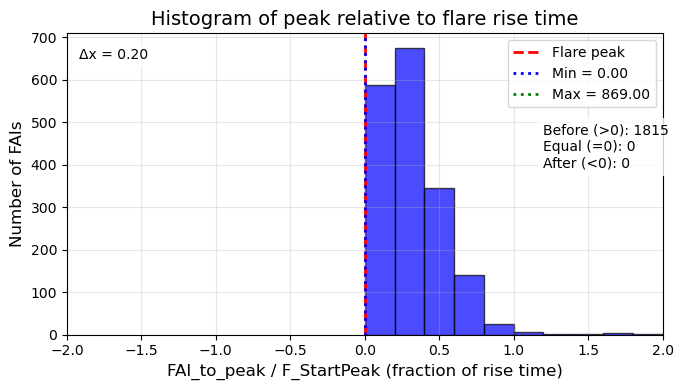

In [28]:
stats2 = plot_relative_histogram(df_associated, 'FAI_to_peak', 
                           delta_x=0.2, figsize=(7,4), 
                           save_plot=True, graphics_dir=graphics_dir, 
                           plot_name=None, dpi=300,
                           text_x=0.8, text_y=0.7,
                           xlim_min=-2, xlim_max=2)

✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/relative_histogram_FAI_to_end_rel_F_StartPeak_dx0.5.png


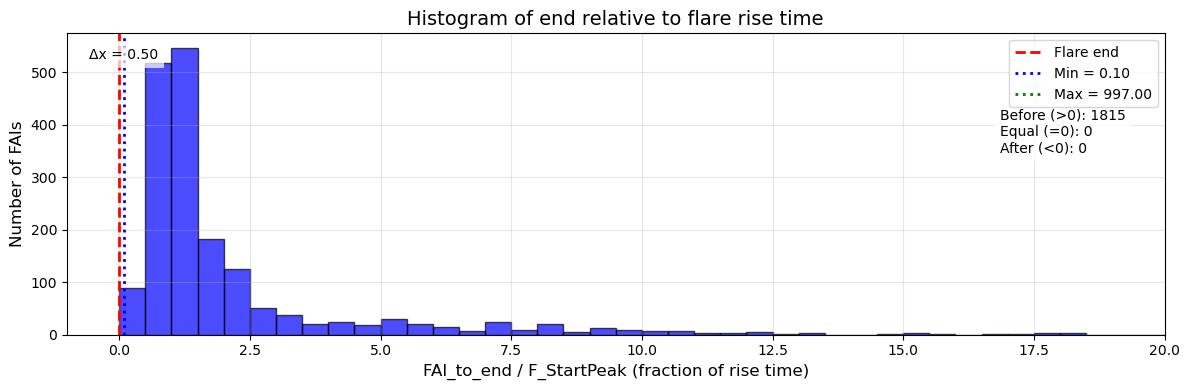

In [18]:
stats3 = plot_relative_histogram(df_associated, 'FAI_to_end', 
                           delta_x=0.5, figsize=(12,4), 
                           save_plot=True, graphics_dir=graphics_dir, 
                           plot_name=None, dpi=300,
                           text_x=0.85, text_y=0.75,
                           xlim_min=-1, xlim_max=20)

## gráficas relativas al rise time por clases

In [19]:
def plot_relative_histogram(df, column_numerator, column_denominator='F_StartPeak', 
                           delta_x=0.1, figsize=(10,5), 
                           save_plot=False, graphics_dir=None, 
                           plot_name=None, dpi=300,
                           text_x=0.03, text_y=0.85,
                           xlim_min=None, xlim_max=None,
                           flare_class=None, class_col='ClassLetter'):
    """
    Crea un histograma relativo al tiempo de rise time del flare, 
    con opción de filtrar por clase (A,B,C,M,X).

    Parámetros nuevos:
    ------------------
    flare_class : str, optional
        'A','B','C','M','X' para filtrar por clase.
    class_col : str, default='ClassLetter'
        Columna donde está la clase del flare.
    """

    df_temp = df.copy()

    # ---------------------------------------------------------
    # 🔹 FILTRO POR CLASE (si se especifica)
    # ---------------------------------------------------------
    if flare_class is not None:
        flare_class = str(flare_class).upper()
        df_temp = df_temp[df_temp[class_col].astype(str).str.upper() == flare_class]
        
        if df_temp.empty:
            print(f"⚠️ No hay flares de clase {flare_class} en la columna '{class_col}'.")
            return None

    # Calcular la columna relativa
    df_temp['relative_column'] = df_temp[column_numerator] / df_temp[column_denominator]
    
    # Datos (eliminar NaN e infinitos)
    x = df_temp['relative_column'].replace([np.inf, -np.inf], np.nan).dropna()
    
    # Definir bins
    min_val = x.min()
    max_val = x.max()
    min_val_ajustado = delta_x * np.floor(min_val / delta_x)
    max_val_ajustado = delta_x * np.ceil(max_val / delta_x)
    bin_edges = np.arange(min_val_ajustado, max_val_ajustado + delta_x, delta_x)

    counts, edges = np.histogram(x, bins=bin_edges)
    bin_width = edges[1] - edges[0]

    # Determinar texto según tipo de referencia
    column_lower = column_numerator.lower()
    if 'peak' in column_lower:
        reference_type = 'peak'
        reference_label = 'Flare peak'
    elif 'end' in column_lower:
        reference_type = 'end'
        reference_label = 'Flare end'
    else:
        reference_type = 'start'
        reference_label = 'Flare start'

    # ---------------------------------------------------------
    # 🔹 Título incluye clase si fue filtrada
    # ---------------------------------------------------------
    if flare_class:
        plot_title = f'Histogram of {reference_type} relative to flare rise time ({flare_class}-class flares)'
    else:
        plot_title = f'Histogram of {reference_type} relative to flare rise time'

    # Gráfica
    plt.figure(figsize=figsize)
    plt.hist(x, bins=bin_edges, color='blue', edgecolor='black', alpha=0.7)

    # Líneas de referencia
    plt.axvline(0, color='red', linestyle='--', linewidth=2, label=reference_label)
    plt.axvline(min_val, color='blue', linestyle=':', linewidth=2, label=f'Min = {min_val:.2f}')
    plt.axvline(max_val, color='green', linestyle=':', linewidth=2, label=f'Max = {max_val:.2f}')

    plt.xlabel(f'{column_numerator} / {column_denominator} (fraction of rise time)', fontsize=12)
    plt.ylabel('Number of FAIs', fontsize=12)
    plt.title(plot_title, fontsize=14)
    plt.legend(loc='upper right')
    plt.grid(alpha=0.3)

    # Aplicar límites personalizados si se pasan
    if xlim_min is not None or xlim_max is not None:
        plt.xlim(left=xlim_min, right=xlim_max)

    # Texto adicional
    plt.text(0.02, 0.95, f'Δx = {bin_width:.2f}',
             transform=plt.gca().transAxes,
             fontsize=10, verticalalignment='top',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    # Estadísticas
    n_before = (x > 0).sum()
    n_equal  = (x == 0).sum()
    n_after  = (x < 0).sum()

    plt.text(text_x, text_y,
             f'Before (>0): {n_before}\nEqual (=0): {n_equal}\nAfter (<0): {n_after}',
             transform=plt.gca().transAxes,
             ha='left', va='top',
             fontsize=10,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

    plt.tight_layout()

    # Guardar imagen
    if save_plot:
        if plot_name is None:
            safe_column_name = f"{column_numerator}_rel_{column_denominator}".replace(' ', '_').replace('/', '_')
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            
            if flare_class:
                plot_name = f"relative_histogram_{flare_class}_{safe_column_name}_dx{delta_x}.png"
            else:
                plot_name = f"relative_histogram_{safe_column_name}_dx{delta_x}.png"

        elif not plot_name.lower().endswith(('.png', '.jpg', '.jpeg', '.pdf', '.svg')):
            plot_name += '.png'
        
        if graphics_dir:
            save_path = os.path.join(graphics_dir, plot_name)
        else:
            save_path = plot_name
        
        os.makedirs(os.path.dirname(save_path) if os.path.dirname(save_path) else '.', exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight')
        print(f"✓ Gráfica guardada en: {save_path}")

    plt.show()

    return {
        'min': min_val,
        'max': max_val,
        'n_before': n_before,
        'n_equal': n_equal,
        'n_after': n_after,
        'total': len(x),
        'bin_width': bin_width,
        'data_used': x
    }


In [20]:
df_associated.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1835 entries, 0 to 2098
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 1835 non-null   object 
 1   observatory          1835 non-null   object 
 2   xrsa                 1835 non-null   float64
 3   xrsb                 1835 non-null   float64
 4   xrsa_corr            1835 non-null   float64
 5   xrsb_corr            1835 non-null   float64
 6   T_cor                1835 non-null   float64
 7   EM_cor               1835 non-null   float64
 8   T_phot               1835 non-null   float64
 9   EM_phot              1835 non-null   float64
 10  EM_cor_norm          1835 non-null   float64
 11  EM_phot_norm         1835 non-null   float64
 12  month                1835 non-null   int64  
 13  day                  1835 non-null   object 
 14  GOES_missing         1835 non-null   bool   
 15  EM_diff              1835 non-null   float6

✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/relative_histogram_C_FAI_to_end_rel_F_StartPeak_dx0.5.png


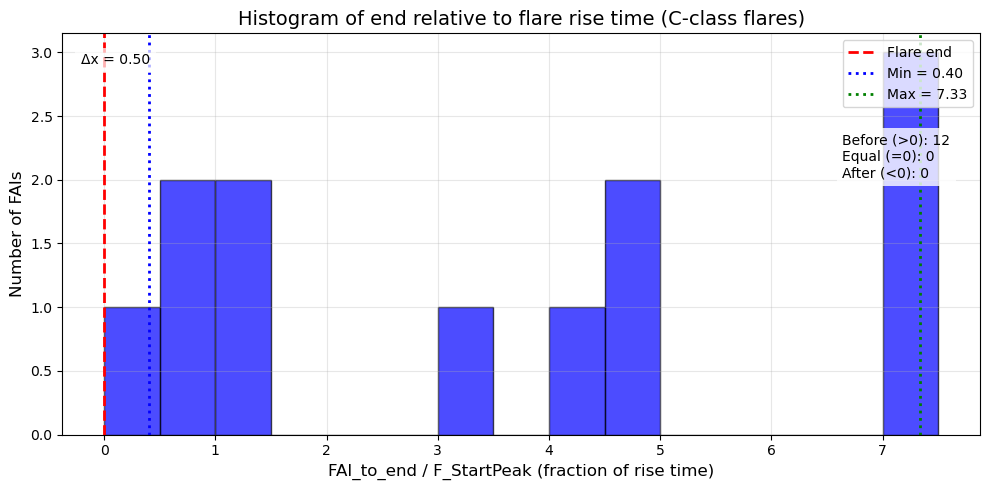

{'min': np.float64(0.4),
 'max': np.float64(7.333333333333333),
 'n_before': np.int64(12),
 'n_equal': np.int64(0),
 'n_after': np.int64(0),
 'total': 12,
 'bin_width': np.float64(0.5),
 'data_used': 57      7.333333
 80      4.285714
 425     0.714286
 618     1.000000
 730     4.625000
 731     4.500000
 1264    0.400000
 1370    7.000000
 1388    1.000000
 1493    0.777778
 1646    7.000000
 1671    3.225806
 Name: relative_column, dtype: float64}

In [21]:
plot_relative_histogram(df_associated, column_numerator='FAI_to_end',
                         column_denominator='F_StartPeak', 
                           delta_x=0.5, figsize=(10,5), 
                           save_plot=True, graphics_dir=graphics_dir, 
                           plot_name=None, dpi=300,
                           text_x=0.85, text_y=0.75,
                           xlim_min=None, xlim_max=None,
                           flare_class='C', class_col='F_ClassLetter')


✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/relative_histogram_M_FAI_to_end_rel_F_StartPeak_dx0.5.png


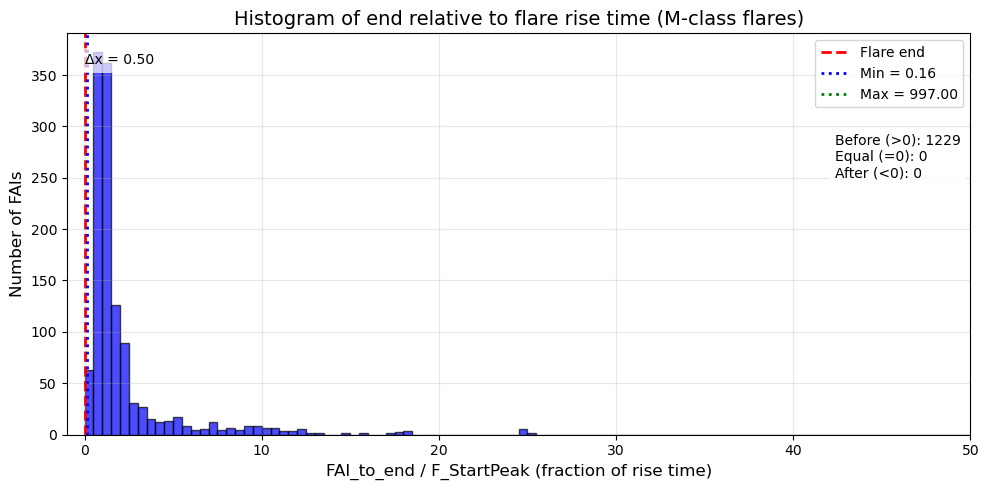

{'min': np.float64(0.15789473684210525),
 'max': np.float64(997.000000000001),
 'n_before': np.int64(1229),
 'n_equal': np.int64(0),
 'n_after': np.int64(0),
 'total': 1229,
 'bin_width': np.float64(0.5),
 'data_used': 4       3.285714
 5       3.214286
 6       3.142857
 7       3.071429
 8       0.966667
           ...   
 2073    1.250000
 2074    1.187500
 2075    1.125000
 2076    1.166667
 2077    1.083333
 Name: relative_column, Length: 1229, dtype: float64}

In [22]:
plot_relative_histogram(df_associated, column_numerator='FAI_to_end',
                         column_denominator='F_StartPeak', 
                           delta_x=0.5, figsize=(10,5), 
                           save_plot=True, graphics_dir=graphics_dir, 
                           plot_name=None, dpi=300,
                           text_x=0.85, text_y=0.75,
                           xlim_min=-1, xlim_max=50,
                           flare_class='M', class_col='F_ClassLetter')

✓ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d07_dur4min/Graphics_filteredend_nooverlap_W30min/relative_histogram_X_FAI_to_end_rel_F_StartPeak_dx0.5.png


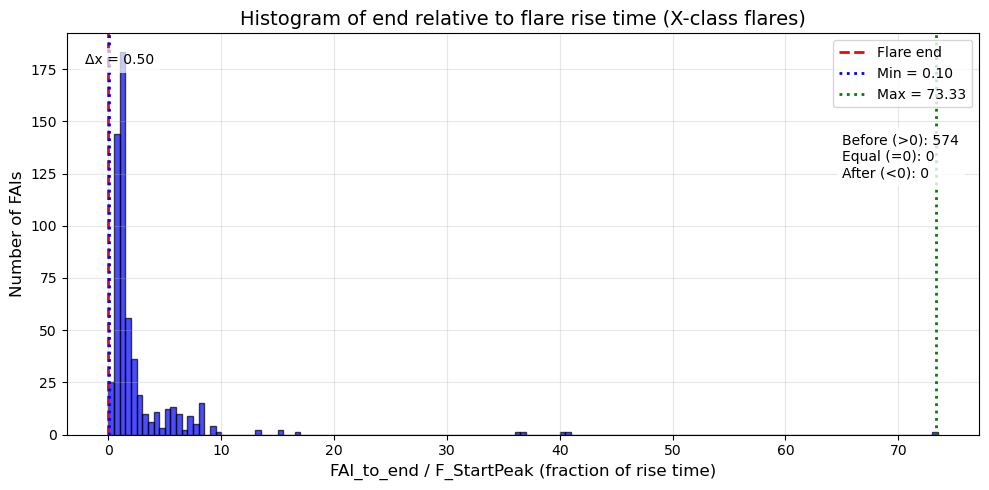

{'min': np.float64(0.09826589595375723),
 'max': np.float64(73.33333333333333),
 'n_before': np.int64(574),
 'n_equal': np.int64(0),
 'n_after': np.int64(0),
 'total': 574,
 'bin_width': np.float64(0.5),
 'data_used': 0       13.250000
 1       13.125000
 2        2.761905
 13       1.666667
 14       1.625000
           ...    
 2094     2.750000
 2095     2.708333
 2096     1.066667
 2097     1.000000
 2098     0.933333
 Name: relative_column, Length: 574, dtype: float64}

In [23]:
plot_relative_histogram(df_associated, column_numerator='FAI_to_end',
                         column_denominator='F_StartPeak', 
                           delta_x=0.5, figsize=(10,5), 
                           save_plot=True, graphics_dir=graphics_dir, 
                           plot_name=None, dpi=300,
                           text_x=0.85, text_y=0.75,
                           xlim_min=None, xlim_max=None,
                           flare_class='X', class_col='F_ClassLetter')

## pruebas

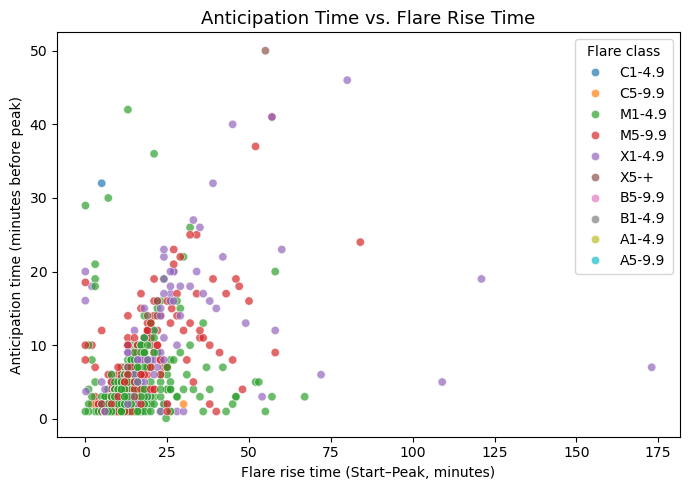

In [24]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_anticipation_time, x="StartPeak", y="AnticipationPeak", hue="ClassGroup", alpha=0.7)
plt.title("Anticipation Time vs. Flare Rise Time", fontsize=13)
plt.xlabel("Flare rise time (Start–Peak, minutes)")
plt.ylabel("Anticipation time (minutes before peak)")
plt.legend(title="Flare class")
plt.tight_layout()
plt.savefig(os.path.join(graphics_dir, "scatter_anticipation_vs_risetime.png"), dpi=300)
plt.show()


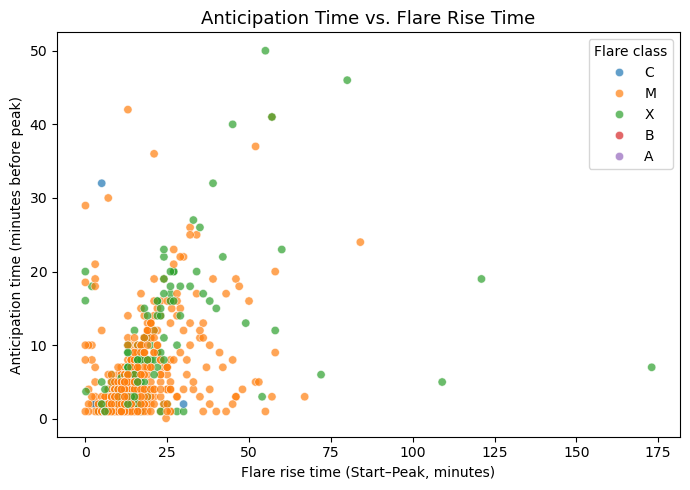

In [25]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_anticipation_time, x="StartPeak", y="AnticipationPeak", hue="ClassLetter", alpha=0.7)
plt.title("Anticipation Time vs. Flare Rise Time", fontsize=13)
plt.xlabel("Flare rise time (Start–Peak, minutes)")
plt.ylabel("Anticipation time (minutes before peak)")
plt.legend(title="Flare class")
plt.tight_layout()
plt.savefig(os.path.join(graphics_dir, "scatter_anticipation_vs_risetime.png"), dpi=300)
plt.show()